# ![Boids Logo](Logo/boid.png) 


# Serial Boid Tests and Benchmarks

**Concurrent Development - Software Development - Year 4, Semester 1 - 2026**  

**South East Technological University**

*23/11/2026*

*Author: Mark Lambert*

This notebook measures the serial update benchmark for 100, 500 and 1000 boids

The benchmark restores the same starting boid state for each iteration and excludes setup and drawing from the timed section

Run the notebook from the repository checkout with Go and the project dependencies installed

---
*Team A.D.A.M - Adam Noonan, Dorian Nowacki, Amelia Hamulewicz, Mark Lambert*

In [1]:
from pathlib import Path
import platform
import re
import shutil
import statistics
import subprocess

# walk up from where jupyter is running, looking for the boids project
project_folder = None
current = Path.cwd()
while True:
    if (current / 'boids' / 'go.mod').exists():
        project_folder = current
        break
    if current == current.parent:   # reached the top of the drive, stop
        break
    current = current.parent
boids_folder = project_folder / 'boids'

# find the Go executable
go_exe = shutil.which('go')

# show current system for testing
print(f'Platform: {platform.platform()}')
print(subprocess.run([go_exe, 'version'], cwd=boids_folder, check=True, text=True, capture_output=True).stdout.strip())
print(subprocess.run([go_exe, 'env', 'GOOS', 'GOARCH'], cwd=boids_folder, check=True, text=True, capture_output=True).stdout.strip())

Platform: Windows-11-10.0.26200-SP0
go version go1.27.4 windows/amd64
windows
amd64


## Serial Benchmark

Each benchmark size is run five times using the `-count=5` flag, `subprocess.run` is used to spawn a new process that runs the benchmark passing in `go test ./tests -run '^$' -bench '^BenchmarkSerial$' -count=5` as the full argument

In [2]:
result = subprocess.run(
    [go_exe, 'test', './tests', '-run', '^$', '-bench', '^BenchmarkSerial$', '-count=5'],
    cwd=boids_folder, text=True, capture_output=True, check=True
)
print(result.stdout)

# pull the timings from each line eg, BenchmarkSerial/100-12   4095   288528 ns/op
timings = {}
for line in result.stdout.splitlines():
    match = re.match(r'^BenchmarkSerial/(\d+)-\d+\s+\d+\s+([\d.]+)\s+ns/op', line)
    if match:
        boid_count = int(match.group(1))
        nanoseconds = float(match.group(2))
        if boid_count in timings:
            timings[boid_count].append(nanoseconds)
        else:
            timings[boid_count] = [nanoseconds]

print('Boids | Runs | Median ns/op')
print('---: | ---: | ---:')
for boid_count in sorted(timings):
    values = timings[boid_count]
    median = statistics.median(values)
    print(f'{boid_count} | {len(values)} | {median:,.0f}')

goos: windows
goarch: amd64
pkg: boids/tests
cpu: AMD Ryzen 5 1600 Six-Core Processor            
BenchmarkSerial/100-12         	    4002	    279279 ns/op
BenchmarkSerial/100-12         	    4342	    277276 ns/op
BenchmarkSerial/100-12         	    4324	    290255 ns/op
BenchmarkSerial/100-12         	    4041	    297369 ns/op
BenchmarkSerial/100-12         	    4112	    297440 ns/op
BenchmarkSerial/500-12         	     169	   7056883 ns/op
BenchmarkSerial/500-12         	     166	   7135466 ns/op
BenchmarkSerial/500-12         	     166	   7104171 ns/op
BenchmarkSerial/500-12         	     170	   7098056 ns/op
BenchmarkSerial/500-12         	     168	   7210225 ns/op
BenchmarkSerial/1000-12        	      37	  28376605 ns/op
BenchmarkSerial/1000-12        	      43	  28843944 ns/op
BenchmarkSerial/1000-12        	      42	  28100300 ns/op
BenchmarkSerial/1000-12        	      43	  28607719 ns/op
BenchmarkSerial/1000-12        	      43	  27933288 ns/op
PASS
ok  	boids/tests	18.888s

B

Doubling the boids from 500 to 1000 roughly quadruples the time, and 100 to 1000 is ~x96, close to the x100 you'd expect if every boid checks every other boid. That confirms the serial implementation is **O(n2)**

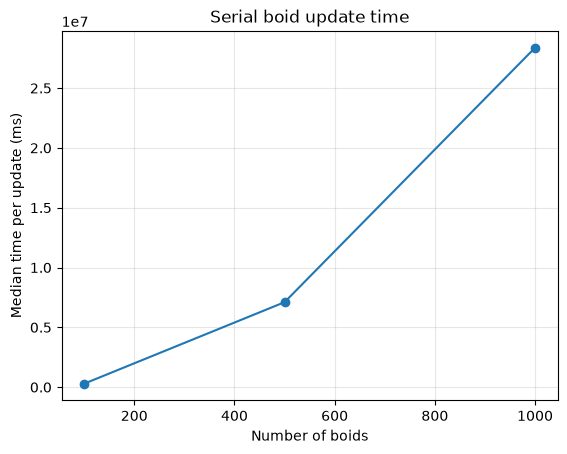

In [10]:
import matplotlib.pyplot as plt

boid_counts = sorted(timings)
median_ms = []
for boid_count in boid_counts:
    median = statistics.median(timings[boid_count])
    median_ms.append(median)

plt.plot(boid_counts, median_ms, marker='o')
plt.xlabel('Number of boids')
plt.ylabel('Median time per update (ms)')
plt.title('Serial boid update time')
plt.grid(alpha=0.3)
plt.show()

## Sources
- Go (2026) testing package: Benchmarks. Available at: https://pkg.go.dev/testing#B (Accessed: 23rd Nov 2026)
- Python Software Foundation (2026) subprocess — Subprocess management. Python 3 documentation. Available at: https://docs.python.org/3/library/subprocess.html (Accessed: 23rd Nov 2026)
- GeeksforGeeks (2025) Python | shutil.which() method. Available at: https://www.geeksforgeeks.org/python/python-shutil-which-method/ (Accessed: 23 November 2026)